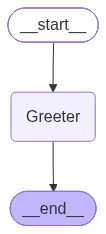

In [5]:
from typing import Dict,TypedDict
from langgraph.graph import StateGraph  
from  IPython.display import Image,display
#StateGraph is a framework that helps you to design and manage the flow of
#the tasks in your application using a graph ds

class AgentState(TypedDict): #Our state schema
    message : str

def greeting_node(state:AgentState) -> AgentState:
    """This is a simple node that adds a greeting node to the state"""
    state["message"] = "Hey " + state["message"] + ", How is your day going?"
    return state
graph = StateGraph(AgentState)
graph.add_node("Greeter",greeting_node)
graph.set_entry_point("Greeter")
graph.set_finish_point("Greeter")
app = graph.compile()
display(Image(app.get_graph().draw_mermaid_png()))

In [6]:
result = app.invoke({"message":"Bob"})

In [7]:
result["message"]

'Hey Bob, How is your day going?'

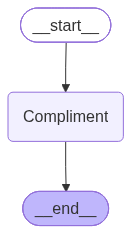

In [1]:
from typing import Dict, TypedDict
from langgraph.graph import StateGraph
from IPython.display import Image,display
class AgentState(TypedDict):
    message : str

def compliment_node(state:AgentState) -> AgentState:
    #"""This is a simple node that adds compliments to a message"""
    state["message"] = state["message"] + " you are doing an amazing job by learning Langgraph"
    return state
graph = StateGraph(AgentState)
graph.add_node("Compliment",compliment_node)
graph.set_entry_point("Compliment")
graph.set_finish_point("Compliment")
app = graph.compile()
display(Image(app.get_graph().draw_mermaid_png()))
result = app.invoke({"message": "Bob"})

In [2]:
result["message"]

'Bob you are doing an amazing job by learning Langgraph'

In [3]:
#Multiple Inputs Graph
from typing import TypedDict,List
from langgraph.graph import StateGraph
class AgentState(TypedDict):
    values : List[int]
    name : str
    result : str
def process_values(state: AgentState) -> AgentState:
    """This is a function that handles multiple different input values"""
    state["result"] = f"Hi there {state["name"]}! Your sum = {sum(state["values"])}"
    return state
graph = StateGraph(AgentState)
graph.add_node("processor",process_values)
graph.set_entry_point("processor")
graph.set_finish_point("processor")
app = graph.compile()

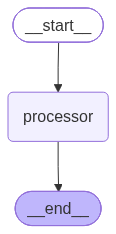

In [4]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [5]:
answers = app.invoke({"values" : [1,2,3,4,5],"name":"Sri Varshini S"})
print(answers["result"])

Hi there Sri Varshini S! Your sum = 15


In [30]:
#Exercise - 2 Multiple inputs Graph
from typing import TypedDict,List
from langgraph.graph import StateGraph
import math
import math
class AgentState(TypedDict):
    name : str
    values : List[int]
    operation : str
    result : str

def perform_operation(state:AgentState) -> AgentState:
    """This is a function that handles multiple different input values"""
    if state["operation"] == "+":
        state["result"] = f"Hi {state["name"]}, your answer is: {sum(state["values"])}"
    elif state["operation"] == "*":
        state["result"] = f"Hi {state["name"]}, your answer is: {math.prod(state["values"])}"
    else:
        state["result"] = "Invalid!"

    return state

graph = StateGraph(AgentState)
graph.add_node("perform_operation",perform_operation)
graph.set_entry_point("perform_operation")
graph.set_finish_point("perform_operation")
app = graph.compile()


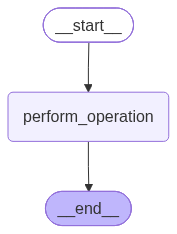

In [31]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [32]:
answers = app.invoke({"name": "Jack Sparrow","values": [1,2,3,4] , "operation": "*"})
#print(answers["result"])

In [33]:
print(answers["result"])

Hi Jack Sparrow, your answer is: 24


In [38]:
#3rd Sequential Graphs

from typing import TypedDict
from langgraph.graph import StateGraph
import math

class AgentState(TypedDict):
    name : str
    age : str
    final : str

def first_node(state:AgentState)->AgentState:
    """This is the first node of our sequential graph"""
    state["final"] = f"Hi {state["name"]}"
    return state

def second_node(state:AgentState) -> AgentState:
    """This is the second node of our sequential graph"""
    state["final"] = state["final"] + f" You are {state["age"]} years old"
    return state


In [39]:
graph = StateGraph(AgentState)
graph.add_node("first_node",first_node)
graph.add_node("second_node",second_node)
graph.set_entry_point("first_node")
graph.add_edge("first_node","second_node")
app = graph.compile()

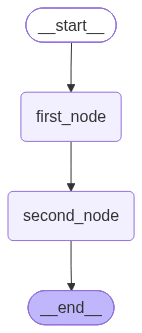

In [40]:
from IPython.display import display,Image
display(Image(app.get_graph().draw_mermaid_png()))

In [41]:
result = app.invoke({"name":"Charlie","age":20})
print(result)

{'name': 'Charlie', 'age': 20, 'final': 'Hi Charlie You are 20 years old'}


In [46]:
from langgraph.graph import StateGraph
from typing import TypedDict
import math

class AgentState(TypedDict):
    name : str
    age : str
    skills : List[str]
    final : str

def first_node(state: AgentState) -> AgentState:
    """This is the third exercise and for Sequential Graph"""
    state["final"] = f"{state["name"]} Welcome to the system!"
    return state

def second_node(state:AgentState) -> AgentState:
    state["final"] = state["final"] + f" You are {state["age"]} years old! "
    return state

def third_node(state:AgentState) -> AgentState:
    state["final"] = state["final"] +  f"You have skills in: {", ".join(state["skills"])}"
    return state

graph = StateGraph(AgentState)
graph.add_node("first_node",first_node)
graph.add_node("second_node",second_node)
graph.add_node("third_node",third_node)
graph.set_entry_point("first_node")
graph.add_edge("first_node","second_node")
graph.add_edge("second_node","third_node")
app = graph.compile()

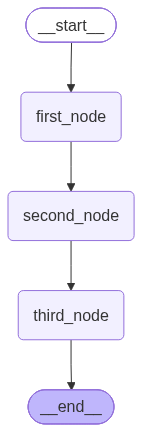

In [47]:
from IPython.display import display,Image
display(Image(app.get_graph().draw_mermaid_png()))

In [48]:
# result = app.invoke({"name":"Charlie","age":20})
# print(result)
result = app.invoke({"name" : "Linda", "age" : 31, "skills" : ["Python","Machine Learning","LangGraph"]})

In [49]:
print(result["final"])

Linda Welcome to the system! You are 31 years old! You have skills in: Python, Machine Learning, LangGraph


In [57]:
#Conditional Logic Graph
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

class AgentState(TypedDict):
    number1 : int
    operation : str
    number2 : int
    finalNumber : int

def adder(state:AgentState) -> AgentState:
    """This is the function for conditional graph that adds two numbers"""
    state["finalNumber"] = state["number1"] + state["number2"]
    return state

def subtracter(state:AgentState) -> AgentState:
    """This is the function for conditional graph that subtracts two numbers"""
    state["finalNumber"] = state["number1"] - state["number2"]
    return state

def decide_next_node(state:AgentState) -> AgentState:
    """This node will select the next node of the graph"""
    if state["operation"] == "+":
        return "addition_operation"
    elif state["operation"] == "-":
        return "subtraction_operation"


In [58]:
graph = StateGraph(AgentState)
graph.add_node("add_node",adder)
graph.add_node("subtract_node",subtracter)
graph.add_node("router",lambda state:state) #pass through function
graph.add_edge(START,"router")
graph.add_conditional_edges(
    "router",
    decide_next_node,
    {
        #Edge : node
        "addition_operation" : "add_node",
        "subtraction_operation" : "subtract_node"
    }
)
graph.add_edge("add_node",END)
graph.add_edge("subtract_node",END)
app = graph.compile()

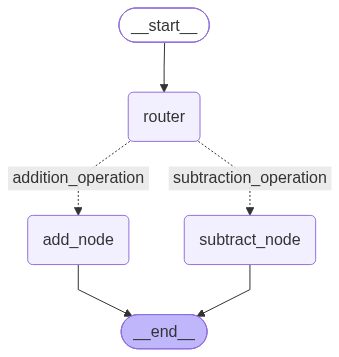

In [59]:
from IPython.display import Image,display
display(Image(app.get_graph().draw_mermaid_png()))

In [60]:
inital_state1 = AgentState(number1=10,operation="-",number2=5)
print(app.invoke(inital_state1))

{'number1': 10, 'operation': '-', 'number2': 5, 'finalNumber': 5}


In [2]:
#AI Agent 4 Exercise
from typing import TypedDict,List
from langgraph.graph import StateGraph,START,END

class AgentState(TypedDict):
    number1 : int
    number2 : int
    operation : str
    number3 : int
    number4 : int
    operation2 : str
    finalNumber : int
    finalNumber2 : int

def adder(state:AgentState) -> AgentState:
    """This node adds the two numbers"""
    state["finalNumber"] = state["number1"] + state["number2"]
    return state

def subtractor(state:AgentState) -> AgentState:
    """This node subtracts the two numbers"""
    state["finalNumber2"] =   state["number1"] + state["number2"]
    return state

def decide_next_node(state:AgentState) -> AgentState:
    """This node will select the next phase"""
    if state["operation"] == "+":
        return "addition_operation"
    elif state["operation"] == "-":
        return "subtraction_operation"

def add_node1(state:AgentState) -> AgentState:
    if state["operation"] == "+":
        return "addition_operation"
    elif state["operation"] == "-":
        return "subtraction_operation"

def adder2(state:AgentState) -> AgentState:
    state["finalNumber2"] = state["number3"] + state["number4"]
    return state

def subtractor2(state:AgentState) -> AgentState:
    state["finalNumber2"] = state["number3"] - state["number4"]
    return state

def decide_next_node1(state:AgentState) -> AgentState:
    if state["operationn2"] == "+":
        return "addition_operation"
    elif state["operation2"] == "-":
        return "subtraction_operation"

graph = StateGraph(AgentState)
graph.add_node("add_node",adder)
graph.add_node("subtract_node",subtractor)
graph.add_node("router", lambda state : state)

graph.add_node("add_node2",adder2)
graph.add_node("subtract_node2",subtractor2)
graph.add_node("router2",lambda state:state)

graph.add_edge(START,"router")
graph.add_conditional_edges(
    "router",
    decide_next_node,
    {
        "addition_operation" : "add_node",
        "subtraction_operation" : "subtract_node"
    }
)

graph.add_edge("add_node","router2")
graph.add_edge("subtract_node","router2")

graph.add_conditional_edges(
    "router2",
    decide_next_node1,
    {
        "addition_operation" : "add_node2",
        "subtraction_operation" : "subtract_node2"
    }
)

graph.add_edge("add_node2",END)
graph.add_edge("subtract_node2",END)
app = graph.compile()

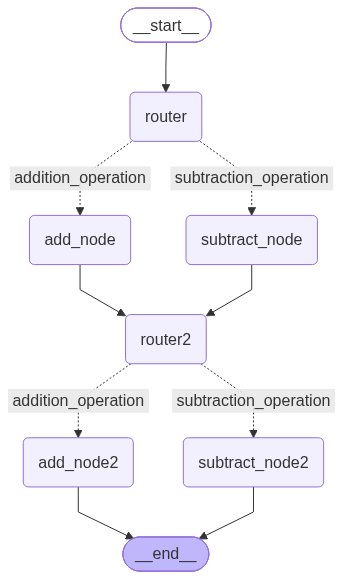

In [3]:
from IPython.display import Image,display
display(Image(app.get_graph().draw_mermaid_png()))

In [4]:
#Looping Graph

from langgraph.graph import StateGraph,START,END
from typing import TypedDict, List,Dict
import random

class AgentState(TypedDict):
    name : str
    number : List[int]
    counter : int

def greeting_node(state:AgentState) -> AgentState:
    """Greeting node which says hi to the person"""
    state["name"] = f"Hi There, {state["name"]}"
    state["counter"] = 0
    return state

def random_node(state:AgentState) -> AgentState:
    """Generates a random number from 0 to 10"""
    state["number"].append(random.randint(0,10))
    state["counter"] += 1
    return state

def should_continue(state:AgentState)->AgentState:
    """Function to do what next"""
    if state["counter"] < 5:
        print("Entering Loop", state["counter"])
        return "loop"
    else:
        return "exit"

graph = StateGraph(AgentState)
graph.add_node("greeting",greeting_node)
graph.add_node("random",random_node)
graph.add_edge("greeting","random")
graph.add_conditional_edges(
    "random",
    should_continue,
    {
        "loop" : "random",
        "exit" : END
    }
)

graph.set_entry_point("greeting")
app = graph.compile()

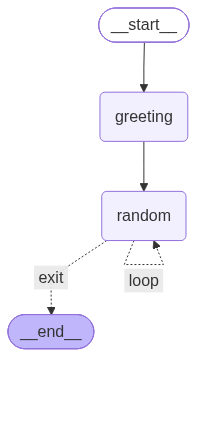

In [5]:
from IPython.display import Image,display
display(Image(app.get_graph().draw_mermaid_png()))

In [7]:
app.invoke({"name":"Vaibhav","number":[],"counter":-1})

Entering Loop 1
Entering Loop 2
Entering Loop 3
Entering Loop 4


{'name': 'Hi There, Vaibhav', 'number': [3, 8, 0, 0, 10], 'counter': 5}

In [9]:
#Exercise 5 - Looping Graph
from typing import TypedDict,List,Dict
from langgraph.graph import StateGraph,START,END
import random

class GameState(TypedDict):
    player_name : str
    target_number : int
    guesses : List[int]
    attempts : int
    hint : str
    lower_bound : int
    upper_bound : int

def setup_node(state:GameState)->GameState:
    state["player_name"] = f"Welcome, {state["player_name"]}"
    state["target_number"] = random.randint(1,20)
    state["guesses"] = []
    state["attempts"] = 0
    state["hint"] = "Game started! Try to guess the number!"
    state["lower_bound"] = 1
    state["upper_bound"] = 20
    print(f"{state["player_name"]} The game has begun. Think of a number between 1 and 20")
    return state

def guess_node(state:GameState)->GameState:
    """Generate a smarter guess based on previous hints"""
    possible_guesses = [i for i in range(state["lower_bound"],state["upper_bound"]+1) if i not in state["guesses"]]
    if possible_guesses:
        guess = random.choice(possible_guesses)
    else:
        guess = random.randint(state["lower_bound"],state["upper_bound"])
    state["guesses"].append(guess)
    state["attempts"] += 1
    print(f"Attempt {state['attempts']}: Guessing {guess} (Current range: {state['lower_bound']}-{state['upper_bound']})")
    return state

def hint_node(state:GameState)->GameState:
    latest_guess = state["guesses"][-1]
    target=state["target_number"]
    if latest_guess < target:
        state["hint"] = f"The number {latest_guess} is too low. Try Higher!"
        state["lower_bound"] = max(state["lower_bound"],latest_guess+1)
        print(f"Hint: {state["hint"]}")
    elif latest_guess > target:
        state["hint"] = f"The number {latest_guess} is too high. Try Lower!"
        state["upper_bound"] = min(state["upper_bound"],latest_guess-1)
        print(f"Hint : {state["hint"]}")
    else:
        state["hint"] = f"You have guessed  the correct number {target} in {state["attempts"]} attempts! "
        print(f"Success! {state["hint"]}")
    return state
def should_continue(state:GameState)->GameState:
    """Determine if we should continue the game or not"""
    """There are two conditions - >= 7 means the maximum number of attempts is reached or the number guessed was correct"""
    latest_guess = state["guesses"][-1]
    if latest_guess == state["target_number"]:
        print("Game OVER! The number was found!")
        return "end"
    elif state["attempts"] >= 7:
        print(f"The maximum number of attempts reached! The number was {state['target_number']}")
        return "end"
    else:
        print(f"CONTINUING: {state['attempts']}/7 attempts used")
        return "continue"



In [13]:
from langgraph.graph import StateGraph,START,END
graph = StateGraph(GameState)
graph.add_node("setup",setup_node)
graph.add_node("guessing",guess_node)
graph.add_node("hint_node",hint_node)
graph.add_edge("setup","guessing")
graph.add_edge("guessing","hint_node")
graph.add_conditional_edges(
    "hint_node",
    should_continue,
    {
        "continue" : "guessing",
        "end" : END
    }
)
graph.set_entry_point("setup")
app = graph.compile()

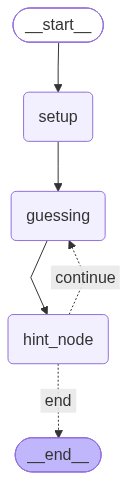

In [14]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [15]:
result = app.invoke({"player_name" : "Sri Varshini ","guesses" : [], "attempts" : 0, "lower_bound": 1, "upper_bound":20})

Welcome, Sri Varshini  The game has begun. Think of a number between 1 and 20
Attempt 1: Guessing 13 (Current range: 1-20)
Hint : The number 13 is too high. Try Lower!
CONTINUING: 1/7 attempts used
Attempt 2: Guessing 10 (Current range: 1-12)
Hint: The number 10 is too low. Try Higher!
CONTINUING: 2/7 attempts used
Attempt 3: Guessing 11 (Current range: 11-12)
Success! You have guessed  the correct number 11 in 3 attempts! 
Game OVER! The number was found!


In [ ]:
#AI AGENT 1 INTRO
from typing import TypedDict, List
from langchain_core.messages import HumanMessage
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START,END
from dotenv import load_dotenv
load_dotenv()

class AgentState(TypedDict):
    messages : List[HumanMessage]

llm = ChatOpenAI(model="gpt-4o")

def process(state:AgentState)->AgentState:
    response = llm.invoke(state["messages"])
    print(f"\nAI: {response.content}")
    return state

graph = StateGraph(AgentState)
graph.add_node("process",process)
graph.add_edge(START,"process")
graph.add_edge("process",END)
agent = graph.compile()
user_input = input("Enter: ")
agent.invoke({"messages"},[HumanMessage(content=user_input)])